# `uncertain` — a playground for the measure axes

Every measure in this library is one configuration of a single expression. You pick a
**unit**, a **horizon**, a **representation**, a **distance**, a **set statistic**, a
**warping** and a **sampler**, and the engine estimates the result — surprisal, entropy and
information value are just particular settings of those seven knobs.

This notebook exists so you can turn the knobs and watch the number move.

**How to use it:** run the cells top to bottom once. Then go back to the cell marked
**THE KNOBS**, change values, and re-run just that cell. Everything after it is a
one-axis-at-a-time comparison you can also edit freely.

Everything runs on GPT-2 (`openai-community/gpt2`, pinned revision). The first run downloads
it (~500 MB) into the Hugging Face cache; after that it loads from disk. CPU is enough.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd

from uncertain import Measure, HFBackend, Stimulus, Sweep, ConfigError
from uncertain.registry import _REGISTRY

print("uncertain", __import__("uncertain").__version__)

# GPT-2 small, pinned to a revision so numbers are reproducible.
backend = HFBackend("openai-community/gpt2",
                    revision="607a30d783dfa663caf39e06633721c8d4cfcd7e")

# A Stimulus is a (context, target) pair of token ids. The target is what was
# actually observed; the measure compares it against what the model expected.
stimulus = Stimulus(context=backend.encode("The capital of France is"),
                    target=backend.encode(" Paris"))
print("context:", stimulus.context, "target:", stimulus.target)

uncertain 0.1.0a2


c:\Users\praney\OneDrive\Desktop\uncertain\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


context: (464, 3139, 286, 4881, 318) target: (6342,)


### What is available on each axis

Read this off the registries rather than trusting a doc comment — it is always current.

In [2]:
for kind in ("unit", "encoder", "distance", "statistic", "warping", "sampler"):
    names = sorted(n for n, _ in _REGISTRY[kind])
    print(f"{kind:10s} {names if names else '(none registered; samplers are injected objects)'}")

unit       ['sentence', 'token', 'word']
encoder    ['layer', 'strings', 'tokens']
distance   ['cosine', 'discrete', 'euclidean', 'ngram_distance', 'ngram_overlap', 'prefix_indicator']
statistic  ['energy', 'mean', 'min']
warping    ['identity', 'neglog']
sampler    (none registered; samplers are injected objects)


## 2. THE KNOBS

**This is the cell to play with.** Change any value, re-run, watch the number move.
Invalid combinations raise `ConfigError` before any model work happens — that is by design,
so the cell catches it and prints the reason instead of a traceback.

In [3]:
UNIT           = "token"        # "token" | "word" | "sentence"
HORIZON        = 1              # H >= 1, counted in UNIT (not in tokens)
REPRESENTATION = "tokens"       # "tokens" | "strings" | "layer:8"
DISTANCE       = "discrete"     # discrete | prefix_indicator | ngram_overlap | ngram_distance
                                # cosine | euclidean  (these two need a vector representation)
STATISTIC      = "energy"       # "energy" | "mean" | "min"
WARPING        = "identity"     # "identity" | "neglog"
SHORT_SAMPLES  = "compare_ragged"   # "compare_ragged" | "pad" | "drop"
ESTIMATOR      = "auto"         # "auto" | "mc" | "exact"
N              = 64             # number of sampled alternatives
SEED           = 0
MODE           = "observed"     # "observed" | "entropy" | "anticipatory"


def describe(result, label=""):
    """Print everything a Result carries. It is never a bare float."""
    se = "n/a" if result.se is None else f"{result.se:.5f}"
    ci = ("n/a" if result.ci_low is None
          else f"[{result.ci_low:.5f}, {result.ci_high:.5f}]")
    print(f"{label}value     = {result.value:.6f}")
    print(f"{' ' * len(label)}se        = {se}      ci = {ci}")
    print(f"{' ' * len(label)}method    = {result.method}   status = {result.status}")
    print(f"{' ' * len(label)}n         = {result.n_requested} requested, "
          f"{result.n_a_used} used on A, {result.n_b_used} on B")
    d = result.diagnostics
    print(f"{' ' * len(label)}truncation= {d.get('truncation_bound')} ({d.get('truncation_status')})")
    print(f"{' ' * len(label)}spec_hash = {result.spec_hash[:16]}...")


def build(**overrides):
    """Build a Measure from the knobs above, with optional per-call overrides."""
    cfg = dict(unit=UNIT, horizon=HORIZON, representation=REPRESENTATION,
               distance=DISTANCE, statistic=STATISTIC, warping=WARPING,
               short_samples=SHORT_SAMPLES, estimator=ESTIMATOR,
               n=N, seed=SEED, mode=MODE)
    cfg.update(overrides)
    return Measure.from_config(backend, **cfg)


try:
    measure = build()
    describe(measure.compute(stimulus))
except ConfigError as exc:
    print("ConfigError (raised before any sampling):\n   ", exc)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6166.26it/s]


value     = 0.953527
se        = 0.00000      ci = [0.95353, 0.95353]
method    = exact   status = ok
n         = 64 requested, 0 used on A, 0 on B
truncation= None (None)
spec_hash = c93bcf108fa82c92...


### Why some combinations are refused

The library type-checks the configuration *before* it samples anything, so a bad pairing
costs milliseconds rather than a GPU job. Two rules cause most refusals:

- **`energy` needs a negative-type dissimilarity.** Mean pairwise distance stays above zero
  even when the two distributions are identical, because it still contains the spread of the
  distribution itself. Energy distance subtracts that off — but only a distance with the
  right mathematical property makes that valid.
- **The representation and the distance must agree on a type.** `tokens` produces unit
  strings; `cosine` wants vectors. Pairing them is refused rather than coerced.

The grid below is computed live, so it cannot drift out of date.

In [4]:
rows = []
for dist in ("prefix_indicator", "ngram_overlap", "ngram_distance", "discrete"):
    row = {"distance": dist}
    for stat in ("mean", "min", "energy"):
        try:
            Measure.from_config(backend, representation="tokens", distance=dist,
                                statistic=stat, n=8,
                                short_samples="compare_ragged")
            row[stat] = "ok"
        except ConfigError as exc:
            row[stat] = "refused" if "negative-type" in str(exc) else "refused*"
    rows.append(row)

print(pd.DataFrame(rows).to_string(index=False))
print("\nRepresentation -> distance type compatibility:")
for rep, dists in (("tokens  ", "prefix_indicator, ngram_overlap, ngram_distance, discrete"),
                   ("layer:N ", "cosine, euclidean  (see section 8)"),
                   ("strings ", "no core distance consumes strings - plugin territory")):
    print(f"  {rep} -> {dists}")

        distance mean min  energy
prefix_indicator   ok  ok refused
   ngram_overlap   ok  ok refused
  ngram_distance   ok  ok refused
        discrete   ok  ok      ok

Representation -> distance type compatibility:
  tokens   -> prefix_indicator, ngram_overlap, ngram_distance, discrete
  layer:N  -> cosine, euclidean  (see section 8)
  strings  -> no core distance consumes strings - plugin territory


## 3. Horizon — how far ahead the comparison looks

`H` counts **units**, not tokens. Generation is token-by-token, but for `unit="word"` the
sampler keeps going until it has seen `H` word boundaries.

Watch the cost as well as the value: `H=1` on token units has a closed form, so the library
solves it exactly and reports `se = 0`. Longer horizons fall back to Monte Carlo.

In [5]:
for h in (1, 2, 3, 5):
    r = build(horizon=h).compute(stimulus)
    se = "exact" if r.se == 0 else f"se={r.se:.4f}"
    print(f"H={h}  value={r.value: .5f}  {se:>12s}  method={r.method}")

H=1  value= 0.95353         exact  method=exact
H=2  value= 0.19238     se=0.0330  method=mc
H=3  value= 0.04346     se=0.0073  method=mc
H=5  value= 0.03125     se=0.0037  method=mc


## 4. Distance and statistic — what "different" means

The distance `g` scores two individual alternatives. The statistic `s` reduces the whole
pair of sets to one number. Keep everything else fixed and vary them.

In [6]:
out = []
for dist in ("discrete", "prefix_indicator", "ngram_overlap", "ngram_distance"):
    for stat in ("mean", "min", "energy"):
        try:
            r = build(horizon=3, distance=dist, statistic=stat, estimator="mc").compute(stimulus)
            out.append({"distance": dist, "statistic": stat, "value": round(r.value, 5),
                        "se": None if r.se is None else round(r.se, 5), "status": r.status})
        except ConfigError:
            out.append({"distance": dist, "statistic": stat, "value": None,
                        "se": None, "status": "refused at config time"})

print(pd.DataFrame(out).to_string(index=False))
print()
print("Note: `min` is a directed statistic - B queries A - and it reports no")
print("uncertainty, hence status/se of `n/a`.")

        distance statistic   value      se                         status
        discrete      mean 0.99829 0.00129          bootstrap_approximate
        discrete       min 0.89062 0.05008          bootstrap_approximate
        discrete    energy 0.04346 0.00730 bounded_energy_ci_bootstrap_se
prefix_indicator      mean 0.06250 0.03050                             ok
prefix_indicator       min 0.00000 0.00000          bootstrap_approximate
prefix_indicator    energy     NaN     NaN         refused at config time
   ngram_overlap      mean 0.04036 0.01024          bootstrap_approximate
   ngram_overlap       min 0.00000 0.00000          bootstrap_approximate
   ngram_overlap    energy     NaN     NaN         refused at config time
  ngram_distance      mean 0.95964 0.01024          bootstrap_approximate
  ngram_distance       min 0.55781 0.06462          bootstrap_approximate
  ngram_distance    energy     NaN     NaN         refused at config time

Note: `min` is a directed statistic -

### Why energy is the default

Draw two sets from the *same* predictive distribution. A good divergence should read zero.
Mean pairwise distance does not — it still contains the entropy of the distribution, so it
reports spread under the name of divergence. Energy distance corrects for exactly that.

In [7]:
from uncertain.registry import resolve
from uncertain import SamplingSpec, UnitSpec, EstimatorSpec
from uncertain.samplers import Sampler
from uncertain.statistics import Mean, Energy

sampler, encoder = Sampler(backend), resolve("encoder", "tokens")
draw = lambda seed: encoder.encode(
    sampler.sample(stimulus.context, 1, SamplingSpec(backend.model_spec, 400, seed), UnitSpec()),
    "compare_ragged")
A, B = draw(1), draw(2)

discrete, est = resolve("distance", "discrete"), EstimatorSpec(method="mc", bootstrap=99)
energy = Energy().estimate(A, B, discrete, est, (11, 12))
mean   = Mean().estimate(A, B, discrete, est, (11, 12))

print("two independent draws from the SAME next-token distribution:")
print(f"  energy distance      = {energy.value: .5f}  (se {energy.se:.5f})  -> indistinguishable from 0")
print(f"  mean pairwise dist.  = {mean.value: .5f}  (se {mean.se:.5f})  -> pinned near 1 - sum p^2, the spread")

two independent draws from the SAME next-token distribution:
  energy distance      =  0.00391  (se 0.00127)  -> indistinguishable from 0
  mean pairwise dist.  =  0.98226  (se 0.00175)  -> pinned near 1 - sum p^2, the spread


## 5. Warping — the `f` on the outside

`identity` reports the statistic itself. `neglog` turns a probability-like quantity into a
surprisal in nats.

A non-affine warping does not commute with averaging: `f` of the mean is not the mean of
`f`. The library reports that gap as `warping_bias` instead of quietly ignoring it, so two
runs that differ only in `n` stay comparable.

In [8]:
for warp in ("identity", "neglog"):
    r = build(horizon=2, distance="prefix_indicator", statistic="mean",
              warping=warp, estimator="mc").compute(stimulus)
    print(f"{warp:9s} value={r.value: .5f}  raw={r.raw_value: .5f}  "
          f"warping_bias={r.warping_bias}")

identity  value= 0.06250  raw= 0.06250  warping_bias=0.0
neglog    value= 2.77259  raw= 0.06250  warping_bias=0.11904761904761905


## 6. Unit — token, word, sentence

The unit is fixed for a whole run, and horizon, granularity and alignment are all expressed
in it. GPT-2's BPE pieces carry their leading space (`" Paris"`), which is what lets the sampler
find word and sentence boundaries.

In [9]:
for unit in ("token", "word", "sentence"):
    try:
        r = build(unit=unit, horizon=2, statistic="mean", estimator="mc").compute(stimulus)
        print(f"{unit:9s} value={r.value: .5f}  se={r.se:.5f}")
    except ConfigError as exc:
        print(f"{unit:9s} refused: {exc}")

# Short samples - those that hit EOS or the token budget before completing H units -
# must be handled by a policy you declare. It changes the number, so it is never a default.
# GPT-2 rarely emits EOS mid-sentence, so eos_fraction is usually ~0 here.
print()
for policy in ("compare_ragged", "pad", "drop"):
    m = Measure.from_config(backend, unit="word", horizon=3, statistic="mean",
                            distance="ngram_distance", short_samples=policy,
                            estimator="mc", n=N, seed=0)
    r = m.compute(stimulus)
    print(f"short_samples={policy:15s} value={r.value: .5f}  n_a_used={r.n_a_used:3d}  "
          f"eos_fraction={r.diagnostics['eos_fraction']:.2f}  "
          f"truncation_bound={r.diagnostics['truncation_bound']:.4f}")

print()
print("  compare_ragged ignores the missing units; pad marks them with a symbol the")
print("  target never contains, pushing short draws further away; drop removes those")
print("  draws entirely - note n_a_used falls. A draw that ended at EOS is complete; only")
print("  draws cut off at H or by the token budget have mass beyond the horizon, so")
print("  `truncation_bound` counts those, not the EOS stops.")

token     value= 0.98242  se=0.00912
word      value= 0.99756  se=0.00266
sentence  value= 1.00000  se=0.00000

short_samples=compare_ragged  value= 0.98503  n_a_used= 64  eos_fraction=0.00  truncation_bound=1.0000
short_samples=pad             value= 0.98505  n_a_used= 64  eos_fraction=0.00  truncation_bound=1.0000
short_samples=drop            value= 0.98486  n_a_used= 64  eos_fraction=0.00  truncation_bound=1.0000

  compare_ragged ignores the missing units; pad marks them with a symbol the
  target never contains, pushing short draws further away; drop removes those
  draws entirely - note n_a_used falls. A draw that ended at EOS is complete; only
  draws cut off at H or by the token budget have mass beyond the horizon, so
  `truncation_bound` counts those, not the EOS stops.


## 7. Sampler — and the sweep that reuses its work

The sampler draws alternatives. Its defaults are the raw model distribution: temperature 1,
`top_k=0`, `top_p=1`, no truncation and no first-step EOS suppression — nothing is inherited
from a generation library's opinions.

The important property is that a sweep **regenerates nothing**. The predictive state after
observing position `t` is the state before position `t+1`, so one sample set per position
serves the whole sentence, and every cell of the grid is a reduction over those same
samples. That also makes the comparisons paired.

In [10]:
grid = Sweep(base=build(horizon=2, statistic="mean", estimator="mc"),
             horizon=[1, 2, 3],
             distance=["discrete", "ngram_distance"],
             statistic=["mean", "min"])

items = [Stimulus(context=backend.encode("The cat sat on the"), target=backend.encode(" mat"),
                  stimulus_id="i1"),
         Stimulus(context=backend.encode("The capital of France is"), target=backend.encode(" Paris"),
                  stimulus_id="i2")]

plan = grid.plan(items)
print("plan:", plan.describe())
print("  -> cells x items rows, but only `sample_requests` generation passes\n")

df = grid.run(items).to_dataframe()
print(df[["stimulus_id", "horizon", "distance", "statistic", "value", "se", "n_a_used"]]
      .to_string(index=False))

plan: {'cells': 12, 'items': 2, 'rows': 24, 'sample_requests': 4, 'anticipated_nested_work': False, 'cache_hits': 0, 'horizons': [3, 3, 2, 2]}
  -> cells x items rows, but only `sample_requests` generation passes

stimulus_id  horizon       distance statistic    value        se  n_a_used
         i1        1       discrete      mean 1.000000       0.0        64
         i1        1       discrete       min 1.000000       0.0        64
         i1        1 ngram_distance      mean 1.000000       0.0        64
         i1        1 ngram_distance       min 1.000000       0.0        64
         i1        2       discrete      mean 1.000000       0.0        64
         i1        2       discrete       min 1.000000       0.0        64
         i1        2 ngram_distance      mean 0.982910  0.003424        64
         i1        2 ngram_distance       min 0.807292  0.021393        64
         i1        3       discrete      mean 1.000000       0.0        64
         i1        3       discrete 

In [11]:
# Sampling knobs live on the sampler, and changing them changes the measure's identity.
base = build(statistic="mean", estimator="mc", horizon=2)
print("default generation:", dict(base.spec.sampling.generation))
print("spec_hash:", base.spec_hash[:16], "...")

warmer = Measure.from_config(backend, unit=UNIT, horizon=2, statistic="mean",
                             estimator="mc", n=N, seed=SEED, short_samples=SHORT_SAMPLES,
                             generation={"temperature": 1.5}, probability="sampling")
print("\nwarmer generation:", dict(warmer.spec.sampling.generation))
print("spec_hash:", warmer.spec_hash[:16], "...  <- a different measure, not a tweak")
print("\nvalue at temperature 1.0:", round(base.compute(stimulus).value, 5))
print("value at temperature 1.5:", round(warmer.compute(stimulus).value, 5))

default generation: {'do_sample': True, 'temperature': 1.0, 'top_k': 0, 'top_p': 1.0, 'num_beams': 1}
spec_hash: 3766489dca9662b1 ...

warmer generation: {'do_sample': True, 'temperature': 1.5, 'top_k': 0, 'top_p': 1.0, 'num_beams': 1}
spec_hash: d92274884aecc58f ...  <- a different measure, not a tweak

value at temperature 1.0: 0.98242
value at temperature 1.5: 1.0


## 8. Representation — hidden layers

`layer:N` encodes each alternative by GPT-2's hidden state at layer `N`, so it pairs with the
vector distances (`cosine`, `euclidean`). Compare an early layer against a middle one.

In [12]:
for layer in ("layer:0", "layer:8"):
    m = Measure.from_config(backend, unit="token", horizon=3, representation=layer,
                            distance="cosine", statistic="energy", n=16,
                            short_samples="compare_ragged")
    r = m.compute(stimulus)
    print(f"{layer}  cosine/energy  value={r.value:.5f}  se={r.se:.5f}")

layer:0  cosine/energy  value=0.05397  se=0.00619
layer:8  cosine/energy  value=0.10881  se=0.01660


## 9. What you get back

A `Result` is never a bare float. It carries the estimate, its standard error and confidence
interval, the `n` that produced it, a status, the diagnostics, and a `spec_hash` that
identifies the exact configuration that produced it — which is what makes a number
reproducible and citable later.

In [13]:
r = build(horizon=3, statistic="mean", estimator="mc").compute(stimulus)

describe(r, label="")
print("\nfull diagnostics:")
for k, v in r.diagnostics.items():
    text = str(v)
    print(f"  {k:26s} {text[:70] + '...' if len(text) > 70 else text}")

value     = 0.998291
se        = 0.00129      ci = [0.99535, 1.00000]
method    = mc   status = bootstrap_approximate
n         = 64 requested, 64 used on A, 64 on B
truncation= 1.0 (bounded_by_unterminated_mass)
spec_hash = 1a4f592dfbe19b1f...

full diagnostics:
  effective_horizons         (3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, ...
  eos_fraction               0.0
  budget_fraction            0.0
  truncation_bound           1.0
  truncation_status          bounded_by_unterminated_mass
  estimand                   finite_horizon
  target                     {'effective_horizons': (3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3...
  random_a                   True
  random_b                   True
  resampling_seed_a          14618246527191957084
  resampling_seed_b          1410566440331878493
  bootstrap_replicates       199
  sample_ids_a               (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,...
  sample_ids_b            

## 10. Seeing the alternatives

`compute` returns the score (a `Result`), not the samples. `measure.alternatives(result)`
loads the sets the score rests on from the store:

- `(A,)` when there is nothing after the target;
- `(A, continuation)` when the horizon extends past the target;
- `()` for exact results, which draw no samples.

`summary()` prints the most frequent alternatives, with their share and mean −log p.
`plot()` draws the same data as a bar chart.

value = 0.98242

64 alternatives, horizon 2, context 'The capital of France is'
 count   share                       -log p  text
     3    4.7% #                       3.76  ' home to'
     3    4.7% #                       4.78  ' Paris.'
     2    3.1% #                       4.73  ' on the'
     2    3.1% #                       6.29  ' now in'
     1    1.6%                        10.48  ' a slave'
     1    1.6%                         5.44  ' known as'

64 alternatives, horizon 1, context 'The capital of France is Paris'
 count   share                       -log p  text
    21   32.8% #######                 0.80  ','
    17   26.6% #####                   1.34  '.'
    10   15.6% ###                     2.11  ' and'
     2    3.1% #                       5.30  ' which'
     2    3.1% #                       6.21  ' for'
     2    3.1% #                       6.23  ' .'


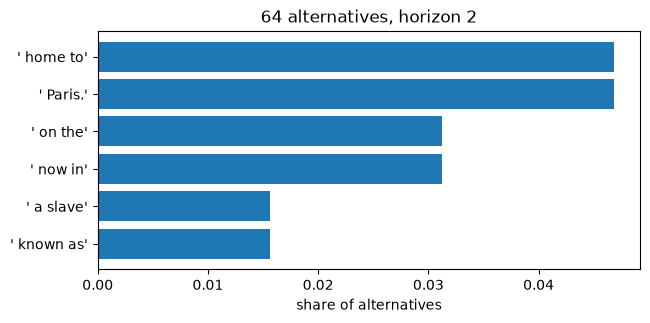

In [14]:
m = build(horizon=2, statistic="mean", estimator="mc")
r = m.compute(stimulus)
a, continuation = m.alternatives(r)      # A ~ p(.|context), continuation ~ p(.|context+target)

print(f"value = {r.value:.5f}\n")
print(a.summary(top=6, decode=backend.decode))
print()
print(continuation.summary(top=6, decode=backend.decode))

try:
    import matplotlib.pyplot as plt
    a.plot(top=6, decode=backend.decode)
    plt.show()
except ImportError:
    print("\n(pip install matplotlib for the bar chart)")

### Whole sentences

`positions(tokens)` turns a sentence into one stimulus per token: `Paris|∅`, `is|Paris`,
`the|Paris is`, ….
Nothing is recomputed along the way:

- **Samples.** They are cached by exact context. The continuation drawn for `is|Paris` comes
  from p(·|Paris is), which is exactly the alternative set `the|Paris is` needs, so N tokens cost
  N+1 sample sets rather than 2N.
- **Model calls.** Every sampled row starts from the same prefix, so the sampler caches
  p(·|context) and runs the model once per distinct context.
- **No reuse across contexts.** `the|Paris` and `the|is` condition on different contexts
  than `the|Paris is`. Their distributions differ, so their samples are not reused for it.

`measure.sentence_summary(stimuli)` prints one line per position: the target, its value
and the top alternatives there. Exact results draw no samples, so they list the most
probable next tokens instead.

In [15]:
from uncertain import positions

# Pass BOS as context: with an empty context only position 0 is conditioned on BOS,
# so later positions would see a different start-of-text than position 0.
sentence = backend.encode("Paris is the capital of France")
words = positions(sentence, context=(backend.bos_token_id,))
for s in words[:3]:
    print(f"position {s.position}: context={s.context}  target={s.target}")

m = build(horizon=3, statistic="mean", estimator="mc")
print()
print(m.sentence_summary(words, top=3))

info = m.sampler._probabilities.cache_info()
print(f"\nsample sets drawn: {m.sampler.calls}  (deepen resumes included)")
print(f"model forward calls: {info.misses}   reused from cache: {info.hits}")

position 0: context=(50256,)  target=(40313,)
position 1: context=(50256, 40313)  target=(318,)
position 2: context=(50256, 40313, 318)  target=(262,)

 pos  target             value  top alternatives
   0  'Paris'             1.00  'in mind.' 2%, '\nIt was' 2%, 'In 1980,' 2%
   1  ' is'               1.00  ' (AFP)' 6%, ' (CNN)' 6%, ' Saint-G' 5%
   2  ' the'              1.00  ' one of the' 5%, ' reporting that two' 2%, ' a place where' 2%
   3  ' capital'          1.00  ' largest city in' 3%, ' third world economy' 2%, ' ambassador of faith' 2%
   4  ' of'               0.97  ' of France,' 12%, ' of France and' 11%, ' of a French' 5%
   5  ' France'           0.99  ' France, and' 3%, ' the Mediterranean and' 2%, ' a region renowned' 2%

sample sets drawn: 12  (deepen resumes included)
model forward calls: 516   reused from cache: 764


### Surprisal and distance for every token

Two measures per token, both from one `Sweep`:

- **Surprisal** (`prefix_indicator` / `mean` / `neglog`, H=1): how unexpected the observed
  token is, −log p in nats. This is exact, so it has no error bar.
- **Energy distance** (`discrete` / `energy`, H=2): how far the model's predicted
  continuations move once the token is observed. This uses Monte Carlo, so bars show ±1
  bootstrap SE. The `ci_low`/`ci_high` columns are a conservative guaranteed bound and
  much wider.

They sit on separate axes because their scales differ. `score_sentences` returns a tidy
frame, one row per token and measure. `plot_sentences` draws one row per sentence, so
the same two calls handle one sentence or many. Needs
matplotlib (`pip install uncertain-altsets[plot]`); about 30 s on CPU with `n=32`.

In [16]:
import matplotlib.pyplot as plt

SURPRISAL = dict(horizon=1, distance="prefix_indicator", statistic="mean", warping="neglog")
DISTANCE = dict(horizon=2, distance="discrete", statistic="energy", warping="identity")
COLORS = {"surprisal (nats)": "#2a78d6", "energy distance": "#eb6834"}


def score_sentences(model, sentences, n=32):
    """Surprisal and energy distance for every token of every sentence, one row each.

    One Sweep: both cells share the same sample sets, and position t's continuation
    is position t+1's alternative set, so nothing is sampled twice.
    """
    items = [s for k, text in enumerate(sentences)
             for s in positions(model.encode(text), context=(model.bos_token_id,),
                                document_id=f"sentence {k+1}")]
    base = Measure.from_config(model, n=n, short_samples="compare_ragged", **SURPRISAL)
    df = Sweep(base, cells=[SURPRISAL, DISTANCE]).run(items).to_dataframe()
    df["token"] = df.stimulus_id.map({s.stimulus_id: model.decode(s.target) for s in items})
    df["measure"] = df.distance.map({"prefix_indicator": "surprisal (nats)",
                                     "discrete": "energy distance"})
    return df[["document_id", "target_start", "token", "measure", "value", "se", "method"]]


def plot_sentences(df):
    """One row per sentence, one column per measure (separate axes: different scales)."""
    docs = list(dict.fromkeys(df.document_id))
    fig, axes = plt.subplots(len(docs), len(COLORS), squeeze=False, sharey="col",
                             figsize=(12, 2.6*len(docs)))
    for row, doc in zip(axes, docs):
        for ax, name in zip(row, COLORS):
            d = df[(df.document_id == doc) & (df.measure == name)].sort_values("target_start")
            x = range(len(d))
            ax.bar(x, d.value.astype(float), width=.6, color=COLORS[name],
                   yerr=d.se.astype(float).fillna(0), ecolor="#6b6b6b", capsize=2, error_kw={"lw": 1})
            ax.set_xticks(x, [t.strip() or repr(t) for t in d.token], rotation=30, ha="right")
            ax.set_title(f"{doc}: {name} (± 1 SE)", loc="left", fontsize=10)
            ax.grid(axis="y", color="#e6e6e6", lw=.8)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig

measure                energy distance  surprisal (nats)
target_start token                                      
0            Paris               0.154             9.937
1             is                 0.084             2.808
2             the                0.070             2.706
3             capital            0.557             2.273
4             of                 0.045             0.180
5             France             0.145             1.096


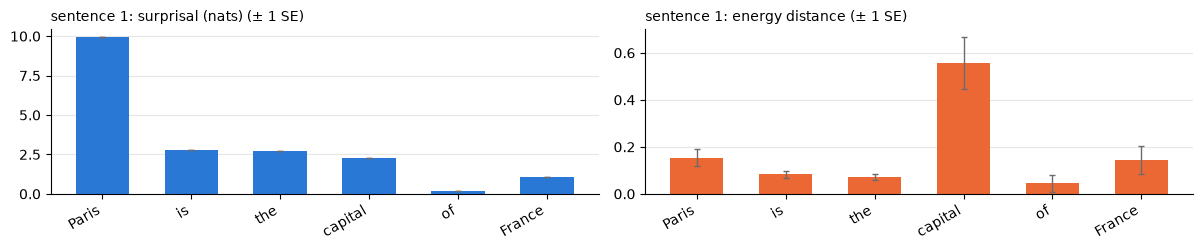

In [17]:
# One sentence, every token: the table is the plot's data, the chart is the quick read.
one = score_sentences(backend, ["Paris is the capital of France"])
print(one.pivot(index=["target_start", "token"], columns="measure", values="value")
      .round(3).to_string())
plot_sentences(one)
plt.show()

measure                              energy distance  surprisal (nats)
document_id target_start token                                        
sentence 1  0            Paris                 0.154             9.937
            1             is                   0.084             2.808
            2             the                  0.070             2.706
            3             capital              0.557             2.273
            4             of                   0.045             0.180
            5             France               0.145             1.096
sentence 2  0            The                   0.064             3.278
            1             cat                  0.080             9.222
            2             sat                  0.178             6.845
            3             on                   0.160             1.493
            4             the                  0.070             0.870
            5             mat                  0.094             5.761
senten

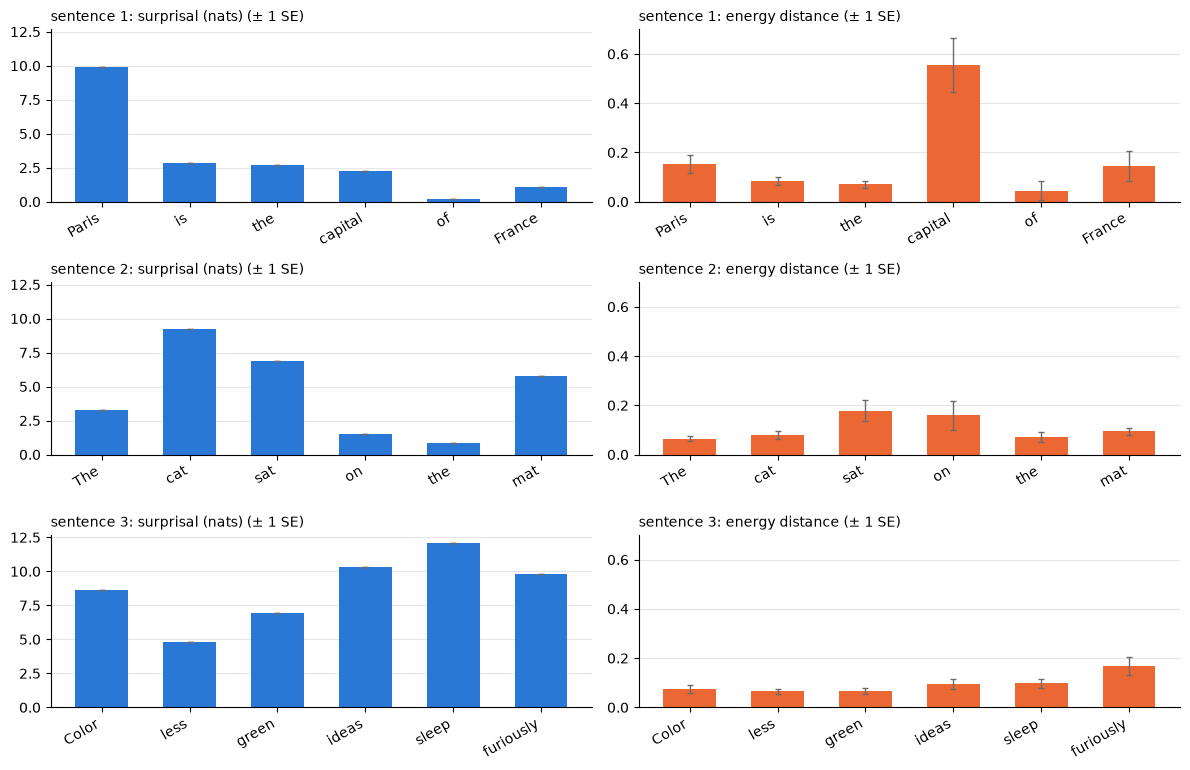

In [18]:
# Many sentences: one Sweep over every token of every sentence, one row of charts each.
# Column y-axes are shared, so bars compare across sentences.
many = score_sentences(backend, ["Paris is the capital of France",
                                 "The cat sat on the mat",
                                 "Colorless green ideas sleep furiously"])
print(many.pivot_table(index=["document_id", "target_start", "token"], columns="measure",
                       values="value").round(3).to_string())
plot_sentences(many)
plt.show()

---

### Where to go next

- Change **THE KNOBS** in section 2 and re-run it — that is the whole point of this file.
- `m.replace(horizon=4)` returns a *new* measure; specs are frozen, so sweeps are safe.
- Every axis is open: implement a protocol, declare your types, register a name. See
  `examples/` for a POS-tag representation, a tree-edit distance, and an
  entailment-clustering statistic — none of which required changing the library.